# WP08 — Gerçek nested split ve deney öncesi hazırlık v1

WP08 kapanmadı. Bu ek, onaylanan protokol incelemesini değiştirmeden gerçek ID/fold listeleri, train sözlükleri, train-only sayısal dönüşümler ve yeni graf nesneleri üretir. **Sınıflandırıcı, tahmin skoru, AP/AUROC veya CI hesaplanmadı.**

Görev, yeni ilaçlarda gözlenen SIDER ilişkilerini sıralamaktır; klinik bireysel risk değildir. Önceki keşifte tüm 62 etiket dağılımı görüldü; değerlendirme ileride iç doğrulama olarak adlandırılmalıdır. Split ve seed, hedef dosyasını bu hazırlıkta açmadan önce kilitlendi.

In [1]:
from pathlib import Path
import json,sys,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP08/experimental_preparation';FIG=ROOT/'reports/figures/WP08/experimental_preparation';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',130);pd.set_option('display.max_columns',22);pd.set_option('display.max_colwidth',100)
def read(n):return pd.read_csv(QA/n,keep_default_na=False)
summary=json.loads((QA/'preparation_summary.json').read_text(encoding='utf-8'));lock=json.loads((QA/'split_lock_v1.json').read_text(encoding='utf-8'))
display(pd.DataFrame([summary]).drop(columns=['protocols','feature_dimensions']))
display(pd.DataFrame([{'seed':lock['specification']['seed'],'outer':5,'inner':3,'kilit_SHA256':lock['specification_sha256'],'onay':'EĞİTİM BEKLİYOR'}]))

,cohort,outer_folds,inner_folds,fit_contexts,graph_objects_new,B1_eligible,B2_eligible,Methenamine,complete_case_only_sensitivity,seed,min_positive_train_drugs,min_positive_train_groups,training_run,negative_sampling,performance_values_computed,WP08_closed,WP09_started,prior_files_preserved,model_fit_approval_pending
0,62,5,3,40,40,54,61,abstain for B1 and B2; retained in inventory,53,20261106,5,2,False,False,False,False,False,399,True


,seed,outer,inner,kilit_SHA256,onay
0,20261106,5,3,9872adf0168ad3ab377994fc346dc3eb553338e68109b9b1cf27ec966ef4bd65,EĞİTİM BEKLİYOR


## 1. Connectivity kilitli dış 5-fold ve iç 3-fold

Atama grup büyüklüğüne göre dengelenir; eşit büyüklüklerde SHA256(seed|group_id) sırası kullanılır. Seed **20261106**, yalnız sabit tarih kodu seçimidir. İkinci seed denemesi veya hedef desteğine göre fold arama yapılmadı. Inner seed=20261106+100×outer_fold. Stress gruplaması, mevcut scaffold OR >=0,8 benzerlik bileşenidir; ana sonuç yerine daha iyi görünürse seçilmeyecek.

,protocol,drug_id,group_id,outer_test_fold
0,primary,DB00199,connectivity_guard_000,3
1,primary,DB00207,connectivity_guard_001,2
2,primary,DB00254,connectivity_guard_002,1
3,primary,DB00259,connectivity_guard_003,3
4,primary,DB00301,connectivity_guard_004,3
5,primary,DB00303,connectivity_guard_005,4
6,primary,DB00319,connectivity_guard_006,5
7,primary,DB00359,connectivity_guard_007,5
8,primary,DB00415,connectivity_guard_008,2
9,primary,DB00417,connectivity_guard_009,2


,context,protocol,outer_fold,inner_fold,train_drugs,validation_drugs,test_drugs,train_graph_drugs,train_graph_proteins,train_graph_edges,chemistry_fit_drugs,protein_fit_accessions
0,primary_o01_final,primary,1,0,49,0,13,49,125,354,43,125
1,primary_o01_i01,primary,1,1,32,17,13,32,92,234,29,92
2,primary_o01_i02,primary,1,2,33,16,13,33,111,250,29,111
3,primary_o01_i03,primary,1,3,33,16,13,33,92,224,28,92
4,primary_o02_final,primary,2,0,49,0,13,49,121,377,43,121
5,primary_o02_i01,primary,2,1,32,17,13,32,92,233,29,92
6,primary_o02_i02,primary,2,2,33,16,13,33,106,270,30,106
7,primary_o02_i03,primary,2,3,33,16,13,33,96,251,27,96
8,primary_o03_final,primary,3,0,50,0,12,50,133,398,43,133
9,primary_o03_i01,primary,3,1,33,17,12,33,103,282,31,103


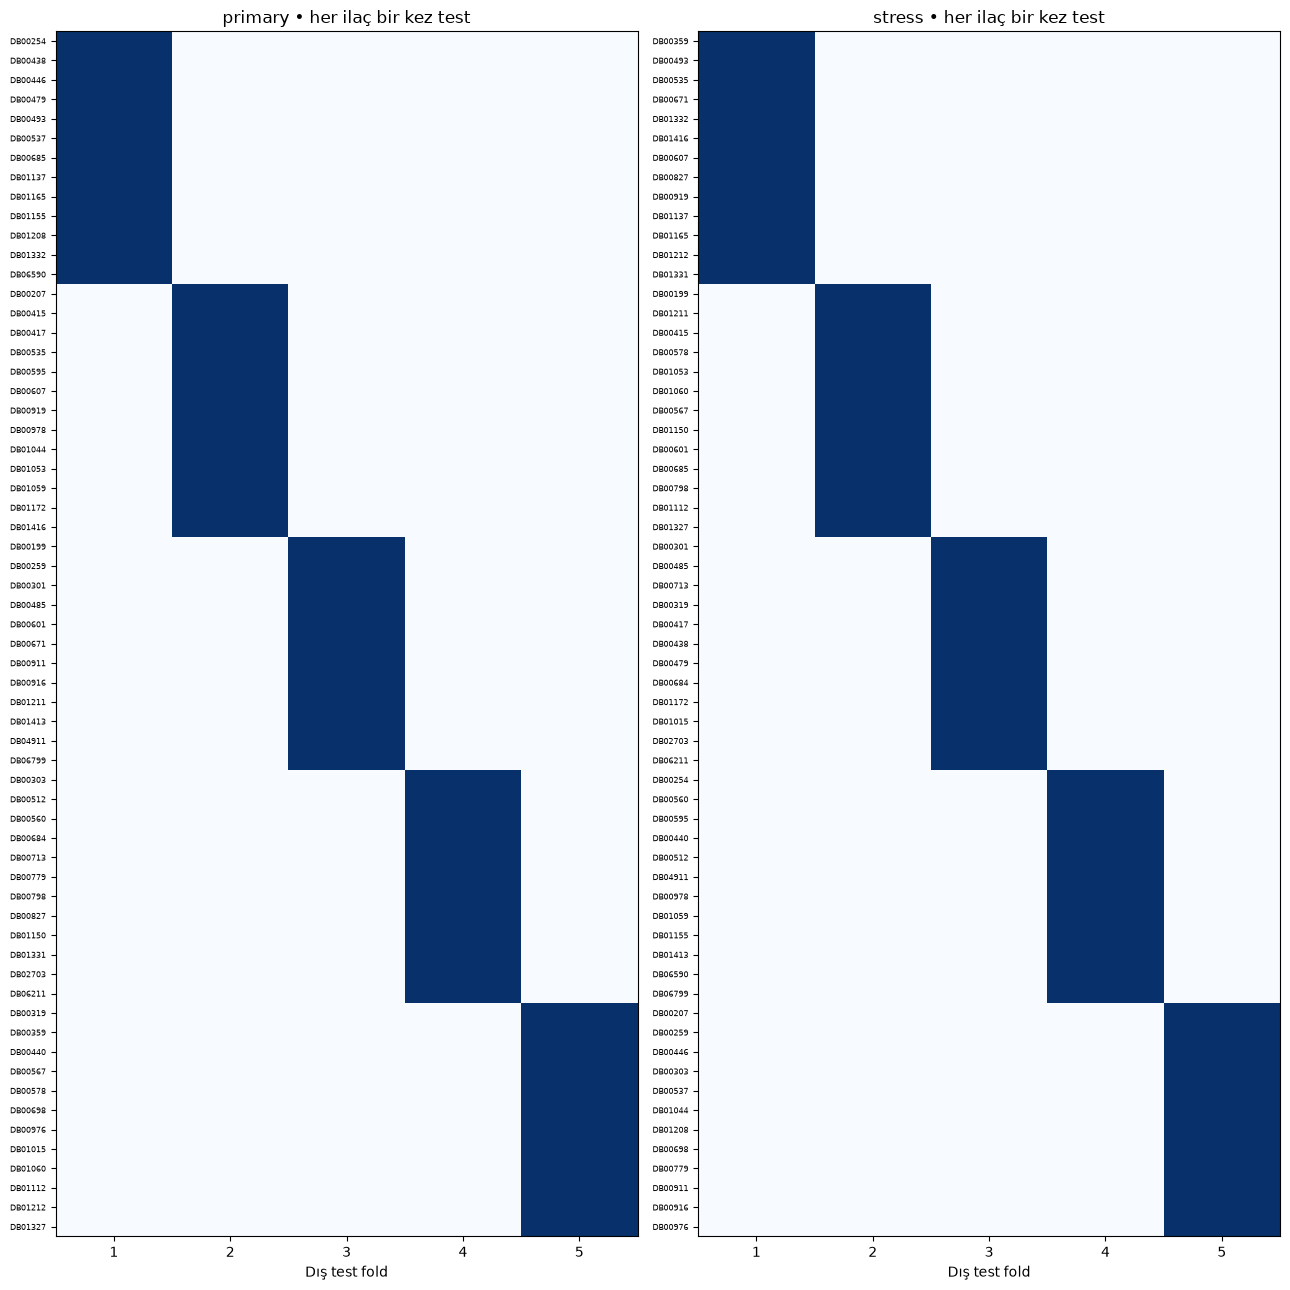

,context,protocol,outer_fold,inner_fold,drug_id,group_id,split
62,primary_o01_i01,primary,1,1,DB00199,connectivity_guard_000,train
63,primary_o01_i01,primary,1,1,DB00207,connectivity_guard_001,train
64,primary_o01_i01,primary,1,1,DB00254,connectivity_guard_002,test
65,primary_o01_i01,primary,1,1,DB00259,connectivity_guard_003,train
66,primary_o01_i01,primary,1,1,DB00301,connectivity_guard_004,train
67,primary_o01_i01,primary,1,1,DB00303,connectivity_guard_005,train
68,primary_o01_i01,primary,1,1,DB00319,connectivity_guard_006,train
69,primary_o01_i01,primary,1,1,DB00359,connectivity_guard_007,train
70,primary_o01_i01,primary,1,1,DB00415,connectivity_guard_008,train
71,primary_o01_i01,primary,1,1,DB00417,connectivity_guard_009,validation


In [2]:
outer=read('outer_membership_v1.csv');parts=read('nested_partitions_v1.csv');contexts=read('context_summary.csv')
display(outer[outer.protocol.eq('primary')]);display(contexts)
names=pd.read_csv(ROOT/'reports/qa/WP07/drug_modality_QA.csv').set_index('drug_id').name.to_dict()
fig,axs=plt.subplots(1,2,figsize=(13,13))
for ax,protocol in zip(axs,['primary','stress']):
    f=outer[outer.protocol.eq(protocol)].sort_values(['outer_test_fold','group_id','drug_id'])
    grid=np.array([[1 if fold==r.outer_test_fold else 0 for fold in range(1,6)] for r in f.itertuples()])
    ax.imshow(grid,aspect='auto',cmap='Blues',vmin=0,vmax=1);ax.set_xticks(range(5),range(1,6));ax.set_yticks(range(62),f.drug_id,fontsize=6);ax.set(xlabel='Dış test fold',title=protocol+' • her ilaç bir kez test')
plt.tight_layout();plt.savefig(FIG/'01_frozen_outer_membership.png',dpi=160);plt.show()
display(parts[parts.context.eq('primary_o01_i01')])

**Yorum:** Gerçek outer test büyüklükleri 13/13/12/12/12; outer train 49/49/50/50/50. Inner train/validation/test ID'leri eksiksiz dosyadadır. Levofloxacin–Ofloxacin her outer ve inner bağlamda aynı tarafta kalır. Outer-final satırlarında validation boş olması beklenir; iç seçim daha sonra tamamlanınca son outer train fit'i yapılacaktır. 40 bağlam, iki protokol × (5 son outer fit + 15 inner fit) demektir; 40 eğitim çalıştırıldığı anlamına gelmez.

## 2. PT destek kuralı: train ilaç ve grup desteği

,context,scope,PT_classes,protocol,outer_fold,inner_fold
0,primary_o01_final,cohort,240,primary,1,0
1,primary_o01_final,B1,220,primary,1,0
2,primary_o01_final,B2,240,primary,1,0
3,primary_o01_final,paired,220,primary,1,0
16,primary_o02_final,cohort,286,primary,2,0
17,primary_o02_final,B1,262,primary,2,0
18,primary_o02_final,B2,286,primary,2,0
19,primary_o02_final,paired,262,primary,2,0
32,primary_o03_final,cohort,319,primary,3,0
33,primary_o03_final,B1,268,primary,3,0


,context,scope,class_id,train_positive_drugs,train_positive_groups,selected_5_drugs_2_groups
0,primary_o01_final,cohort,C0000731,6,6,True
1,primary_o01_final,cohort,C0000737,39,39,True
2,primary_o01_final,cohort,C0000768,2,2,False
3,primary_o01_final,cohort,C0000786,1,1,False
4,primary_o01_final,cohort,C0000833,3,3,False
5,primary_o01_final,cohort,C0001122,2,2,False
6,primary_o01_final,cohort,C0001125,1,1,False
7,primary_o01_final,cohort,C0001175,2,2,False
8,primary_o01_final,cohort,C0001339,2,2,False
9,primary_o01_final,cohort,C0001807,2,2,False


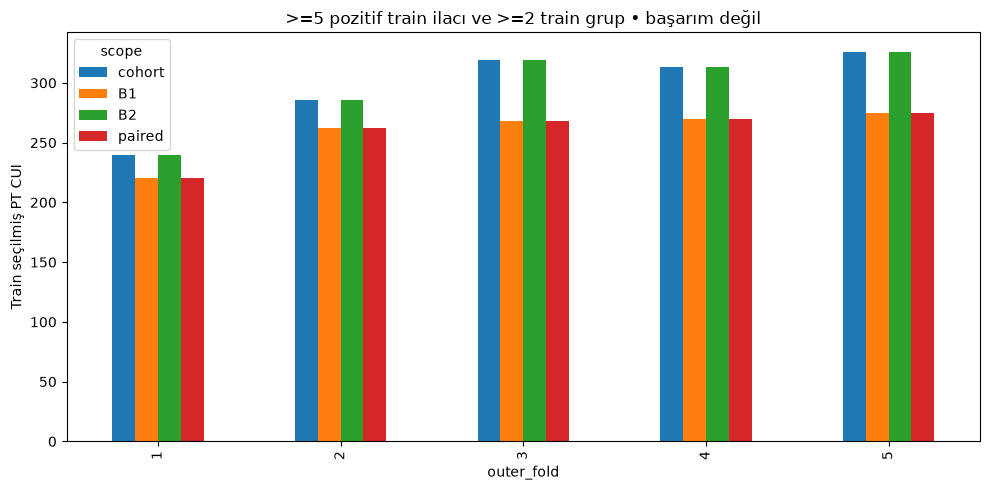

inner_fold,1,2,3
outer_fold,,,
1,157,180,134
2,169,226,169
3,189,162,209
4,211,155,206
5,190,198,170


In [3]:
vocab=read('vocabulary_counts.csv');supports=read('train_PT_support.csv')
final=vocab[vocab.protocol.eq('primary') & vocab.inner_fold.eq(0)];display(final)
display(supports[supports.context.eq('primary_o01_final')].head(16))
pivot=final.pivot(index='outer_fold',columns='scope',values='PT_classes')[['cohort','B1','B2','paired']]
fig,ax=plt.subplots(figsize=(10,5));pivot.plot.bar(ax=ax);ax.set(ylabel='Train seçilmiş PT CUI',title='>=5 pozitif train ilacı ve >=2 train grup • başarım değil');plt.tight_layout();plt.savefig(FIG/'02_train_vocabularies.png',dpi=160);plt.show()
inner=vocab[vocab.protocol.eq('primary') & vocab.inner_fold.gt(0) & vocab.scope.eq('paired')].pivot(index='outer_fold',columns='inner_fold',values='PT_classes');display(inner)

**Yorum:** 5/2 kuralı sonuç başarımına bakılmadan düşük destek ve tek grup bağımlılığını sınırlayan operasyonel adaydır; istatistiksel güç veya klinik geçerlilik garantisi değildir. Kohort train sözlüğü ayrıca saklanır. B1/B2 için kullanılabilir inputu olan train ilaçlarında destek yeniden sayılır; eşleştirilmiş hedefler iki model sözlüğünün train-only kesişimidir. Bu payda ayrıntısı son onay tablosunda açıkça belirtilir. Outer train sözlüğü inner validation desteğine kopyalanmaz; her inner train yeniden kendi sözlüğünü belirler.

Test etiketleri sözlüğü genişletemez. Seçili sözlük dışındaki test pozitiflerinin kapsamı ileride ayrıca raporlanmalı; sınıf elemesini metrik yükseltme yöntemi gibi yorumlamamalıyız. Tarihsel 30 değişmeyen, semantik uyarılı ayrı karşılaştırmadır.

## 3. Model bazlı girdi kapsamı ve abstention

,drug_id,name,model,eligible,abstention_reason,chemistry_available,protein_available,molecule_review,review_flags,cohort_retained,planned_prediction_status
0,DB00199,Erythromycin,B1,True,,True,True,False,,True,PREDICTION_NOT_RUN
1,DB00199,Erythromycin,B2,True,,True,True,False,,True,PREDICTION_NOT_RUN
2,DB00207,Azithromycin,B1,True,,True,True,False,,True,PREDICTION_NOT_RUN
3,DB00207,Azithromycin,B2,True,,True,True,False,,True,PREDICTION_NOT_RUN
4,DB00254,Doxycycline,B1,True,,True,True,False,,True,PREDICTION_NOT_RUN
5,DB00254,Doxycycline,B2,True,,True,True,False,,True,PREDICTION_NOT_RUN
6,DB00259,Sulfanilamide,B1,True,,True,True,False,,True,PREDICTION_NOT_RUN
7,DB00259,Sulfanilamide,B2,True,,True,True,False,,True,PREDICTION_NOT_RUN
8,DB00301,Flucloxacillin,B1,True,,True,True,False,,True,PREDICTION_NOT_RUN
9,DB00301,Flucloxacillin,B2,True,,True,True,False,,True,PREDICTION_NOT_RUN


,kohort,tahmine_girdi_uygun,abstention
model,,,
B1,62,54,8
B2,62,61,1


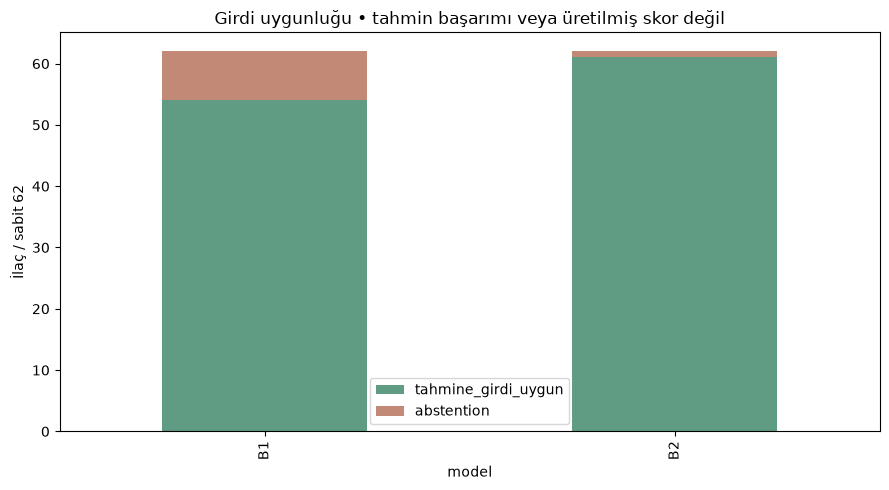

,drug_id,name,model,eligible,abstention_reason,chemistry_available,protein_available,molecule_review,review_flags,cohort_retained,planned_prediction_status
52,DB00684,Tobramycin,B1,True,,True,False,False,,True,PREDICTION_NOT_RUN
53,DB00684,Tobramycin,B2,True,,True,False,False,,True,PREDICTION_NOT_RUN
122,DB06799,Methenamine,B1,False,abstain_no_QC_approved_chemistry,False,False,True,unspecified_atom_stereo,True,ABSTAIN
123,DB06799,Methenamine,B2,False,abstain_no_personalized_input,False,False,True,unspecified_atom_stereo,True,ABSTAIN


In [4]:
eligible=read('prediction_eligibility.csv');display(eligible)
coverage=eligible.groupby('model').agg(kohort=('drug_id','nunique'),tahmine_girdi_uygun=('eligible','sum'));coverage['abstention']=coverage.kohort-coverage.tahmine_girdi_uygun;display(coverage)
fig,ax=plt.subplots(figsize=(9,5));coverage[['tahmine_girdi_uygun','abstention']].plot.bar(stacked=True,ax=ax,color=['#5f9c83','#c28a76']);ax.set(ylabel='İlaç / sabit 62',title='Girdi uygunluğu • tahmin başarımı veya üretilmiş skor değil');plt.tight_layout();plt.savefig(FIG/'03_abstention_coverage.png',dpi=160);plt.show()
display(eligible[eligible.drug_id.isin(['DB06799','DB00684'])])

**Yorum:** B1 kimya-only için 54 ilaçta girdi var, sekiz inceleme molekülünde abstention var. B2 rol bazlı protein+kimya için 61 ilaçta en az bir dal var; **Methenamine için iki modelde de abstention** uygulanır. Tobramycin B2'de kimya dalıyla kalır. “Uygun” henüz skor üretildiği anlamına gelmez. 62 ID envanterde korunur; 53 complete-case yalnız duyarlılık alt grubudur. Maskeler kaynak girdisinden gelir, yan etki etiketinden türetilmez.

## 4. Train-only dönüşüm ve 4 ayrı protein rolü

,context,chemistry_fit_drugs,protein_fit_accessions
0,primary_o01_final,43,125
1,primary_o01_i01,29,92
2,primary_o01_i02,29,111
3,primary_o01_i03,28,92
4,primary_o02_final,43,121
5,primary_o02_i01,29,92
6,primary_o02_i02,30,106
7,primary_o02_i03,27,96
8,primary_o03_final,43,133
9,primary_o03_i01,31,103


,model,alan_sayisi,ID_ve_PT_girdisi
0,B1,6,False
1,B2,234,False


,kimya_fit_drug_id
0,DB00199
1,DB00207
2,DB00259
3,DB00301
4,DB00303
5,DB00319
6,DB00359
7,DB00415
8,DB00440
9,DB00485


,protein_fit_accession
0,A0A0H2XJ39
1,D6R448
2,O15439
3,O43193
4,O76082
5,O94956
6,O95342
7,P00374
8,P00484
9,P00551


,mean,scale
MW,465.383483,241.284859
LogP,0.431170,2.609331
HBD,3.896552,3.763205
HBA,8.620690,4.700798
TPSA,156.774828,87.671607


,chem__MW,chem__LogP,chem__HBD,chem__HBA,chem__TPSA
DB00199,1.113014,0.519072,0.293220,1.144340,0.423571
DB00207,1.175426,0.563183,0.293220,1.144340,0.265823
DB00254,-0.086800,-0.298456,0.558951,0.080691,0.283389
DB00259,-1.215055,-0.197357,-0.503972,-1.195688,-0.805219
DB00301,-0.047680,0.864839,-0.503972,-0.557499,-0.502270


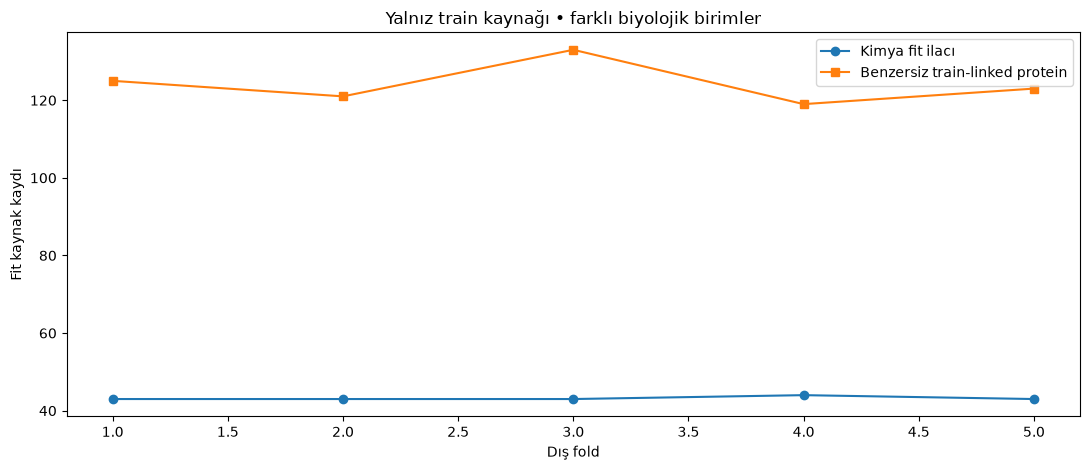

In [5]:
fits=json.loads((QA/'transform_fit_sources_and_statistics.json').read_text(encoding='utf-8'));schema=json.loads((QA/'feature_schema_v1.json').read_text(encoding='utf-8'))
display(contexts[['context','chemistry_fit_drugs','protein_fit_accessions']]);display(pd.DataFrame([{'model':m,'alan_sayisi':len(cols),'ID_ve_PT_girdisi':False} for m,cols in schema['features'].items()]))
example='primary_o01_i01';fit=fits[example]
display(pd.DataFrame({'kimya_fit_drug_id':fit['chemistry_fit_drug_ids']}));display(pd.DataFrame({'protein_fit_accession':fit['protein_fit_accessions']}))
display(pd.DataFrame({'mean':fit['chemistry']['mean'],'scale':fit['chemistry']['scale']}))
arr=np.load(QA/'features'/(example+'.npz'),allow_pickle=False)
display(pd.DataFrame(arr['B2'][:5,:5],index=arr['drug_ids'][:5],columns=schema['features']['B2'][:5]))
fig,ax=plt.subplots(figsize=(11,4.8));c=contexts[(contexts.protocol.eq('primary')) & contexts.inner_fold.eq(0)];ax.plot(c.outer_fold,c.chemistry_fit_drugs,'o-',label='Kimya fit ilacı');ax.plot(c.outer_fold,c.protein_fit_accessions,'s-',label='Benzersiz train-linked protein');ax.set(xlabel='Dış fold',ylabel='Fit kaynak kaydı',title='Yalnız train kaynağı • farklı biyolojik birimler');ax.legend();plt.tight_layout();plt.savefig(FIG/'04_transform_fit_scope.png',dpi=160);plt.show()

**Yorum:** Gerçek dönüşüm istatistikleri fit edildi, sınıflandırıcı eğitilmedi. Kimya yalnız QC-onaylı train ilaçları, protein yalnız train ilacı ilişkilerindeki benzersiz accession'lar üzerinden standardize edilir. Test ilacının yalnız kendisinde bulunan proteini fit kaynağı olamaz; aynı protein train ilacında da varsa train kaynak olarak bulunması meşrudur.

B1: 5 kimya+1 maske=6 alan. B2: 5 kimya+4×56 ayrı rol özeti+5 availability maskesi=234 alan. Eksik dalda standardize edilmiş **nötr yer tutucu 0 ve açık maske** kullanılır; bu gerçek MW/AAC sıfırı veya eksik dizi doldurma değildir. Ham/clean kaynak eksikleri korunur; 80 context hiç eklenmez. Her rol önce train ölçeğine göre dönüştürülür, sonra o ilacın ilişkili proteinleri ortalanır. Kimlikler metadata'dadır. Bu yüksek boyut küçük örneklemde düzenlileştirme gerektirir; LR/MLP/RF seçimi eğitim onayında kalır.

## 5. Yeni train-only graflar ve metrik hesaplanabilirliği

,context,train_drugs,validation_drugs,test_drugs,train_graph_drugs,train_graph_proteins,train_graph_edges
0,primary_o01_final,49,0,13,49,125,354
1,primary_o01_i01,32,17,13,32,92,234
2,primary_o01_i02,33,16,13,33,111,250
3,primary_o01_i03,33,16,13,33,92,224
4,primary_o02_final,49,0,13,49,121,377
5,primary_o02_i01,32,17,13,32,92,233
6,primary_o02_i02,33,16,13,33,106,270
7,primary_o02_i03,33,16,13,33,96,251
8,primary_o03_final,50,0,12,50,133,398
9,primary_o03_i01,33,17,12,33,103,282


,context,relation,source_type,target_type,edge_count
0,primary_o01_final,target,drug,protein,173
1,primary_o01_final,enzyme,drug,protein,61
2,primary_o01_final,transporter,drug,protein,102
3,primary_o01_final,carrier,drug,protein,18
4,primary_o01_i01,target,drug,protein,114
5,primary_o01_i01,enzyme,drug,protein,35
6,primary_o01_i01,transporter,drug,protein,72
7,primary_o01_i01,carrier,drug,protein,13
8,primary_o01_i02,target,drug,protein,116
9,primary_o01_i02,enzyme,drug,protein,49


,context,model,split,cohort_drugs,eligible_drugs,abstained_drugs,train_selected_PT_classes,observed_positive_pairs,unobserved_pairs_NOT_verified_negatives,classes_no_observed_positive,classes_all_observed_positive,proxy_AUROC_evaluable_classes,metric_values_computed,meaning,observed_source_positive_pairs_all_PT,out_of_vocab_observed_positive_pairs,train_and_split_proxy_AUROC_possible_classes
2,primary_o01_final,B1,test,13,11,2,220,919,1501,7,5,208,False,observed-record support only; unknown not verified negative,1633,714,208
5,primary_o01_final,B2,test,13,13,0,240,1212,1908,5,5,230,False,observed-record support only; unknown not verified negative,2014,802,230
26,primary_o02_final,B1,test,13,11,2,262,657,2225,54,1,207,False,observed-record support only; unknown not verified negative,902,245,207
29,primary_o02_final,B2,test,13,13,0,286,916,2802,49,1,236,False,observed-record support only; unknown not verified negative,1262,346,236
50,primary_o03_final,B1,test,12,11,1,268,748,2200,48,0,220,False,observed-record support only; unknown not verified negative,989,241,219
53,primary_o03_final,B2,test,12,11,1,319,777,2732,78,0,241,False,observed-record support only; unknown not verified negative,989,212,240
74,primary_o04_final,B1,test,12,10,2,270,660,2040,50,4,216,False,observed-record support only; unknown not verified negative,953,293,216
77,primary_o04_final,B2,test,12,12,0,313,786,2970,64,4,245,False,observed-record support only; unknown not verified negative,1086,300,245
98,primary_o05_final,B1,test,12,11,1,275,846,2179,59,12,204,False,observed-record support only; unknown not verified negative,1028,182,204
101,primary_o05_final,B2,test,12,12,0,326,895,3017,90,8,228,False,observed-record support only; unknown not verified negative,1054,159,228


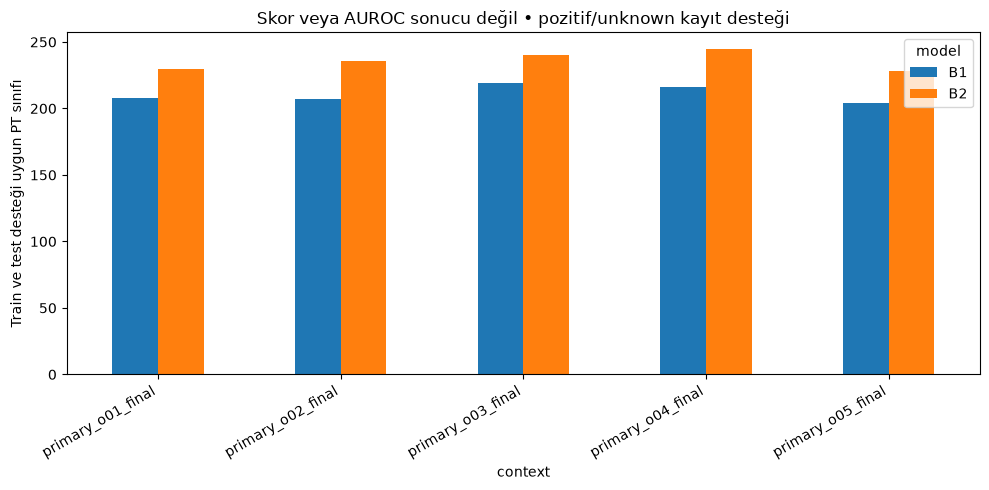

size  sum
context           model           
primary_o01_final B1      220  220
                  B2      240  240
primary_o01_i01   B1      157  157
                  B2      171  171
primary_o01_i02   B1      180  178
                  B2      193  191
primary_o01_i03   B1      134  134
                  B2      163  163
primary_o02_final B1      262  262
                  B2      286  286

,context,model,split,eligible_drugs,fixed_categories,classes_no_observed_positive,classes_all_observed_positive,proxy_AUROC_evaluable_classes,metric_values_computed
0,primary_o01_final,B1,validation,0,30,30,0,0,False
1,primary_o01_final,B1,test,11,30,1,3,26,False
2,primary_o01_final,B2,validation,0,30,30,0,0,False
3,primary_o01_final,B2,test,13,30,1,3,26,False
4,primary_o01_i01,B1,validation,14,30,0,3,27,False
5,primary_o01_i01,B1,test,11,30,1,3,26,False
6,primary_o01_i01,B2,validation,16,30,0,2,28,False
7,primary_o01_i01,B2,test,13,30,1,3,26,False
8,primary_o01_i02,B1,validation,14,30,0,0,30,False
9,primary_o01_i02,B1,test,11,30,1,3,26,False


In [6]:
display(contexts[['context','train_drugs','validation_drugs','test_drugs','train_graph_drugs','train_graph_proteins','train_graph_edges']])
display(read('graph_edge_counts.csv').head(12))
evaluation=read('metric_evaluability_NO_scores.csv');ev=evaluation[evaluation.context.isin(final.context) & evaluation.split.eq('test')];display(ev)
fig,ax=plt.subplots(figsize=(10,5));ev.pivot(index='context',columns='model',values='train_and_split_proxy_AUROC_possible_classes').plot.bar(ax=ax);ax.set(ylabel='Train ve test desteği uygun PT sınıfı',title='Skor veya AUROC sonucu değil • pozitif/unknown kayıt desteği');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.savefig(FIG/'05_metric_support_not_scores.png',dpi=160);plt.show()
display(read('proxy_trainability_NO_model_fit.csv').groupby(['context','model']).proxy_classifier_fittable_if_approved.agg(['size','sum']).head(10))
display(read('secondary30_evaluability_NO_scores.csv').head(10))

**Yorum:** 40 yeni graf, her bağlamın train ilaçlarını ve yalnız onların dört tip DrugBank ilişkisini içerir. WP07 `.pt` dosyaları kullanılmaz; validation/test drug düğümleri veya ileri/ters bağlantıları, PPI ve SE hedef kenarları yoktur. Train-linked protein evreni kullanılır; 141 proteinlik bütün-kohort registry veya 80 context'e otomatik genişleme yoktur. İleride query inferansı ayrı yapılmalıdır.

“Hesaplanabilir” sütunu sınıfta hem gözlenen pozitif hem unknown bulunduğunu söyler; unknown gerçek negatif değildir. Train'de yalnız tek proxy sonucu bulunan sınıfta LR fit'i de yapılamaz; bu sınıflar için önsel olasılık uydurulmadan NA planlandı. Seçilen 5/2 sözlüğü ile ikili proxy modelinin fit edilebilirliği ayrı dosyalardır. Sıfır pozitif veya bütün ilaçlarda pozitif olan test sınıfları ayırt edici proxy metriği için NA kalır. **Burada AP/AUROC değeri hesaplanmadı.** Gelecekte onaylanırsa AP/AUROC yalnız gözlenen kaynak kayıtlarını sıralayan proxy ölçüm olacak; klinik bireysel risk, gerçek negatif özgüllüğü veya biyolojik kalibrasyon olmayacaktır. Folda göre değişen sözlük kapsamları gizlenmeden raporlanmalıdır.

## 6. Model eğitimi öncesi tek kısa karar tablosu

In [7]:
display(read('final_pretraining_decisions.csv'))
gate=json.loads((QA/'training_gate.json').read_text(encoding='utf-8'));display(pd.DataFrame([gate]))
import plotly.graph_objects as go
f=outer[outer.protocol.eq('primary')].sort_values('drug_id')
heat=np.array([[int(r.outer_test_fold==i) for i in range(1,6)] for r in f.itertuples()]);hover=np.array([[r.drug_id+' '+names[r.drug_id]+' | '+r.group_id for i in range(5)] for r in f.itertuples()])
fig=go.Figure(go.Heatmap(z=heat,x=list(range(1,6)),y=f.drug_id,text=hover,hovertemplate='%{text}<br>Outer fold %{x}; test üyeliği=%{z}<extra></extra>',colorscale='Blues',showscale=False))
fig.update_layout(title='Kilitli connectivity outer fold kimlikleri • model sonucu değil',height=1400,width=1000)
fig.write_html(FIG/'frozen_fold_membership_interactive.html',include_plotlyjs=True,full_html=True)

,detay,hazirlanan_veya_onerilen_v1,egitim_onayi
0,Seed ve fold kilidi,"20261106; tek kez etiket körü 5 dış/3 iç; inner seed=base+100*outer; primary connectivity, stres...",Hazırlık v1 kilitlendi; seed için son eğitim onayı bekliyor
1,PT destek paydası,>=5 pozitif kullanılabilir train ilacı ve >=2 train grup; kohort sözlüğü ayrıca; B1/B2 ortak hed...,5/2 adayının ve kullanılabilir-train paydasının onayı bekliyor
2,Proxy varsayımı ve ölçüm,"Yalnız SIDER kayıt sıralaması; unknown doğrulanmış negatif değil; birincil drug-macro AP, micro/...",Proxy eğitim/ölçüm varsayımı onaylanmadan sınıflandırıcı ve skor yok
3,Abstention ve masked blok,B1 kimya yoksa abstain; B2 iki modalite yoksa abstain; Methenamine için iki modelde de tahmin yo...,Abstention kullanıcı yönüyle uygulandı; maskeli nötr kodlama ve kapsam kıyasının son onayı
4,Başlangıç learner / iç seçim,"Eşleştirilmiş B1/B2 için düzenlileştirilmiş LR önerisi; C={0.1,1,10}, class_weight=None; iç-fold...",Öneri; LR/ayar seçimi onayı bekliyor. RF/MLP ayrıca deney gerektirir
5,"NA, fallback ve kıyas","Train iki proxy sonucu taşımıyorsa sınıfı fit etme, NA; val/test pozitif veya unknown yoksa ayır...",Fallback olasılığı veya ortak önsel üretilmedi; NA/ortak kıyas politikasının onayı
6,ATC ve ek analizler,ATC başlangıç matrise eklenmedi; WP02 kaynağıyla ayrı varyant önerisi. 53 complete-case yalnız a...,ATC/ek learner eğitimleri ayrı onay; WP09 kapalı


,preparation_version,split_specification_sha256,status,model_training_authorized,performance_authorized,unknown_semantics,primary_estimand,pending_table,WP08_closed,WP09_authorized
0,WP08-preparation-v1,9872adf0168ad3ab377994fc346dc3eb553338e68109b9b1cf27ec966ef4bd65,AWAITING_FINAL_METHOD_APPROVAL,False,False,unobserved != verified biological negative,ranking observed SIDER drug-adverse-effect records for unseen drugs,final_pretraining_decisions.csv,False,False


**Kapanış:** Bu hazırlıkta gerçek split, train kaynaklı sözlük/standardizasyon ve train-only graf dosyaları üretildi. Negatif örnekleme, classifier fit, tahmin ve performans yoktur. Son karar tablosu [hazırlık raporunda](../reports/WP08_EXPERIMENTAL_PREPARATION.md) da bulunur. Kullanıcı model eğitimi ve kalan yöntem ayrıntılarını onaylamadan deney başlatılmaz. WP08 açık kalır, WP09'a geçilmez.

[Train-only dönüşüm için resmi açıklama](https://scikit-learn.org/stable/common_pitfalls.html), [AP tanımı](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [AUROC tanımı](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).